In [11]:
import os

import jax
import jax.numpy as jnp

os.environ["CUDA_VISIBLE_DEVICES"] = "3"

HORIZON = 5
INITIAL_STATE = jnp.array([2.0, 4.0])  # position, velocity

In [12]:
from hcnn.training.train_bundle import TrainBundle

system = TrainBundle.build_double_integrator()

In [13]:
def solve_discreate_are(
    state_matrix: jax.Array,
    input_matrix: jax.Array,
    state_cost: jax.Array,
    input_cost: jax.Array,
    tol: float = 1e-8,
) -> tuple[jax.Array, jax.Array]:
    """
    Solve the discrete algebraic Riccati equation (DARE)
    using policy iteration.
    The DARE is given by:
    X = A^T * X * A
      - (A^T * X * B) * (R + B^T * X * B)^(-1) * (B^T * X * A) + Q
    where:
    - A is the state transition matrix
    - B is the input matrix
    - Q is the state cost matrix
    - R is the input cost matrix
    - X is the solution to the DARE
    """

    @jax.jit
    def policy_improvement(riccati_matrix):
        return jnp.linalg.solve(
            input_cost + input_matrix.T @ riccati_matrix @ input_matrix,
            input_matrix.T @ riccati_matrix @ state_matrix,
        )

    @jax.jit
    def policy_evaluation(riccati_matrix, gain_matrix):
        return (
            state_cost
            + state_matrix.T @ riccati_matrix @ state_matrix
            - state_matrix.T @ riccati_matrix @ input_matrix @ gain_matrix
        )

    gain_matrix = jnp.zeros((input_matrix.shape[1], state_matrix.shape[0]))
    riccati_matrix = state_cost
    for _ in range(500):
        gain_matrix = policy_improvement(riccati_matrix)
        new_riccati_matrix = policy_evaluation(riccati_matrix, gain_matrix)
        if jnp.linalg.norm(new_riccati_matrix - riccati_matrix) < tol:
            break
        riccati_matrix = new_riccati_matrix
    return riccati_matrix, gain_matrix


riccati_matrix, gain_matrix = solve_discreate_are(
    state_matrix=system.sys_dynamics.state_matrix,  # type: ignore is linear sys
    input_matrix=system.sys_dynamics.action_matrix,  # type: ignore is linear sys
    state_cost=system.sys_costs.state_cost_matrix,  # type: ignore is quadratic
    input_cost=system.sys_costs.action_cost_matrix,  # type: ignore is quadratic
)

In [14]:
from hcnn.optimization_layer import Rollout


def scan_fn(state, _):
    action = -gain_matrix @ state
    next_state = system.sys_dynamics(state, action)
    return next_state, (state, action)


states, actions = jax.lax.scan(scan_fn, INITIAL_STATE, None, length=HORIZON)[1]

raw_rollout = Rollout(states, actions)

In [15]:
raw_rollout

Rollout(states=Array([[ 2.        ,  4.        ],
       [ 4.441943  ,  0.88388634],
       [ 4.5678735 , -0.6320256 ],
       [ 3.676952  , -1.1498175 ],
       [ 2.5352883 , -1.1335099 ]], dtype=float32), actions=Array([[-3.1161137 ],
       [-1.5159119 ],
       [-0.51779187],
       [ 0.01630759],
       [ 0.24142581]], dtype=float32))

In [16]:
from hcnn.optimization_layer import ProjectionPhi, ProjectionProblem
from hcnn.solver import SQPParameters, sqp_solve

projection_problem = ProjectionProblem.factory(
    sys_dynamics=system.sys_dynamics,
    sys_constraints=system.sys_constraints,
    horizon=HORIZON,
)
phi = ProjectionPhi(
    states_ref=raw_rollout.states,
    actions_ref=raw_rollout.actions,
    initial_state=INITIAL_STATE,
)
sqp_problem = projection_problem.replace(phi=phi)
sqp_parameters = SQPParameters()

In [17]:
from hcnn.solver import SQPParameters

sqp_parameters = SQPParameters()
x_star, sqp_info = sqp_solve(sqp_problem, sqp_parameters)
optvar = projection_problem.x_to_optvar(x_star)
proj_rollout = Rollout(
    states=optvar.states,
    actions=optvar.actions,
)

In [18]:
sqp_info

SQPInfo(primal_residual=Array(2.9087067e-05, dtype=float32), dual_residual=Array(5.888939e-05, dtype=float32), iterations_lin=Array(290., dtype=float32, weak_type=True), iterations_nonlin=Array(1, dtype=int32, weak_type=True), rho_base_mult=Array(1., dtype=float32), converged_flag=Array(True, dtype=bool), avg_step_size=Array(1., dtype=float32, weak_type=True))

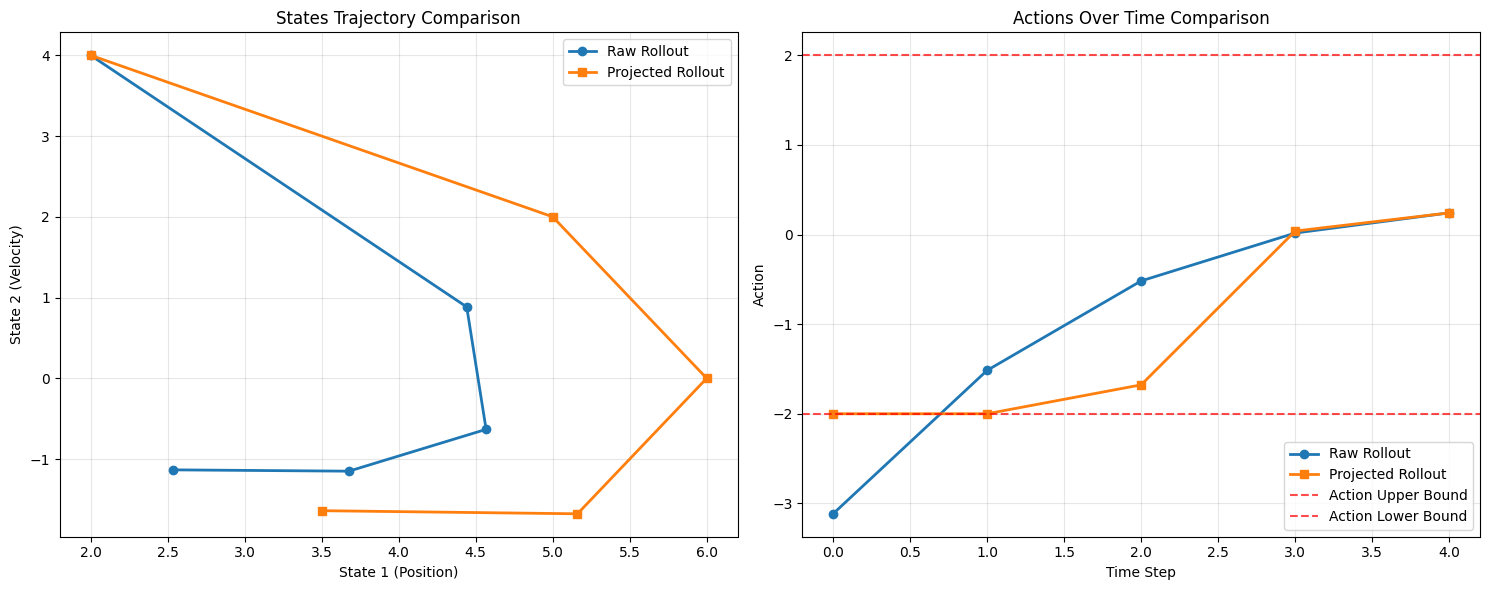

Trajectory Comparison Summary:
Max difference in states: 1.484184
Max difference in actions: 1.159741
Raw rollout actions outside bounds: 2
Projected rollout actions outside bounds: 3


In [19]:
from matplotlib import pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot states comparison
ax1.plot(
    raw_rollout.states[:, 0],
    raw_rollout.states[:, 1],
    "o-",
    label="Raw Rollout",
    markersize=6,
    linewidth=2,
)
ax1.plot(
    proj_rollout.states[:, 0],
    proj_rollout.states[:, 1],
    "s-",
    label="Projected Rollout",
    markersize=6,
    linewidth=2,
)
ax1.set_xlabel("State 1 (Position)")
ax1.set_ylabel("State 2 (Velocity)")
ax1.set_title("States Trajectory Comparison")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot actions comparison
time_steps = range(len(raw_rollout.actions))
ax2.plot(
    time_steps,
    raw_rollout.actions[:, 0],
    "o-",
    label="Raw Rollout",
    markersize=6,
    linewidth=2,
)
ax2.plot(
    time_steps,
    proj_rollout.actions[:, 0],
    "s-",
    label="Projected Rollout",
    markersize=6,
    linewidth=2,
)
ax2.axhline(
    y=2.0, color="r", linestyle="--", alpha=0.7, label="Action Upper Bound"
)
ax2.axhline(
    y=-2.0, color="r", linestyle="--", alpha=0.7, label="Action Lower Bound"
)
ax2.set_xlabel("Time Step")
ax2.set_ylabel("Action")
ax2.set_title("Actions Over Time Comparison")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print numerical comparison
print("Trajectory Comparison Summary:")
print(
    f"Max difference in states: {jnp.max(jnp.abs(raw_rollout.states - proj_rollout.states)):.6f}"
)
print(
    f"Max difference in actions: {jnp.max(jnp.abs(raw_rollout.actions - proj_rollout.actions)):.6f}"
)
print(
    f"Raw rollout actions outside bounds: {jnp.sum(jnp.abs(raw_rollout.actions) > 1.0)}"
)
print(
    f"Projected rollout actions outside bounds: {jnp.sum(jnp.abs(proj_rollout.actions) > 1.0)}"
)